### 0. Required run configuration — single episode

Set CONFIG["data"]["episode_path"] to the episode folder under data/raw before running.
You may enter its ID, a repository-relative path, or its absolute folder path.
The notebook uses the matching existing data/processed/lidar_episode_v1/<ID>/episode.npz.
An empty path stops execution; an unexported episode produces a clear missing-file error.

All other model/training settings are copied from the current baseline notebook.
Training uses the first configured fraction of scans; validation uses the later scans.
This measures later scans of the same path, rather than generalization to other paths.

In [16]:
from pathlib import Path
import copy
import json
import math
import random
import sys

# Edit these explicit settings before running the notebook.
# Missing, blank, or invalid settings stop execution before data loading/training.
CONFIG = {
    "paths": {
        "repo_root": r"A:\Projects\ARES",
        "output_root": r"A:\Projects\ARES\results\output_directoryZ\single_episode",
    },
    "run": {"name": "CNN_MLP_BASELINE_SINGLE_EPISODE", "seed": 42},
    "data": {
        # REQUIRED: episode ID, data/raw/<ID>, or absolute data/raw/<ID> folder.
        "episode_path": r"A:\Projects\ARES\data\raw\f9ab72ef-e1d7-4479-8faa-03bb5b36776c",
        "train_fraction": 0.8,
        "val_fraction": 0.2,
        "split_policy": "chronological",
        "verify_hashes": True,
    },
    "model": {
        "input_features": 12,
        "hidden_activation": "gelu",
        "encoder_hidden": [1024, 4096],
        "latent_channels": 128,
        "latent_length": 45,
        "decoder_channels": [128, 64, 64, 32, 15],
        "decoder_lengths": [90, 179, 358, 716, 716],
        "kernel_sizes": [5, 5, 3, 3, 1],
        "upsample_mode": "linear",
        "align_corners": False,
        "output_activation": "identity",
    },
    "training": {
        "optimizer": "adamw",
        "loss": "mse",
        "epochs": 2000,
        "batch_size": 32,
        "learning_rate": 1e-3,
        "weight_decay": 1e-3,
        "betas": [0.9, 0.999],
        "eps": 1e-8,
        "patience": 25,
        "save_every_n_epochs": 25,
    },
    "scheduler": {
        "name": "cosine",
        "t_max_epochs": 2000,
        "min_lr": 1e-6,
    },
    "runtime": {
        "gpu_index": 0,
        "amp_dtype": "bf16",
        "num_workers": 0,
        "pin_memory": True,
        "persistent_workers": False,
        "cudnn_benchmark": True,
        "matmul_precision": "high",
        "fused_adamw": True,
    },
    "plots": {
        "dpi": 160,
        "scan_index": 0,
        "range_min_m": 0.0,
        "range_max_m": 7.0,
        "colormap": "viridis",
    },
}


def validate_config(config):
    required = {
        "paths": ("repo_root", "output_root"),
        "run": ("name", "seed"),
        "data": ("episode_path", "train_fraction", "val_fraction",
                 "split_policy", "verify_hashes"),
        "model": ("input_features", "hidden_activation", "encoder_hidden", "latent_channels", "latent_length",
                  "decoder_channels", "decoder_lengths", "kernel_sizes",
                  "upsample_mode", "align_corners", "output_activation"),
        "training": ("optimizer", "loss", "epochs", "batch_size", "learning_rate", "weight_decay",
                     "betas", "eps", "patience", "save_every_n_epochs"),
        "scheduler": ("name", "t_max_epochs", "min_lr"),
        "runtime": ("gpu_index", "amp_dtype", "num_workers", "pin_memory",
                    "persistent_workers", "cudnn_benchmark", "matmul_precision",
                    "fused_adamw"),
        "plots": ("dpi", "scan_index", "range_min_m", "range_max_m", "colormap"),
    }
    for section, keys in required.items():
        if section not in config or not isinstance(config[section], dict):
            raise ValueError(f"Missing configuration section: {section}")
        for key in keys:
            if key not in config[section]:
                raise ValueError(f"Missing configuration: {section}.{key}")

    def check_filled(value, path):
        if value is None or (isinstance(value, str) and not value.strip()):
            raise ValueError(f"Fill configuration before execution: {path}")
        if isinstance(value, dict):
            for key, item in value.items():
                check_filled(item, f"{path}.{key}")
        elif isinstance(value, (list, tuple)):
            if not value:
                raise ValueError(f"Empty configuration: {path}")
            for i, item in enumerate(value):
                check_filled(item, f"{path}[{i}]")
        elif isinstance(value, float) and not math.isfinite(value):
            raise ValueError(f"Non-finite configuration: {path}")
    check_filled(config, "CONFIG")

    def integer(value, label, minimum):
        if isinstance(value, bool) or not isinstance(value, int) or value < minimum:
            raise ValueError(f"{label} must be an integer >= {minimum}.")

    def number(value, label, minimum, *, positive=False):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"{label} must be numeric.")
        if not math.isfinite(value) or value < minimum or (positive and value == minimum):
            raise ValueError(f"Invalid numeric value: {label}")

    for section, keys, minimum in (
        ("run", ("seed",), 0),
        ("training", ("epochs", "batch_size", "patience"), 1),
        ("training", ("save_every_n_epochs",), 0),
        ("scheduler", ("t_max_epochs",), 1),
        ("runtime", ("gpu_index", "num_workers"), 0),
        ("plots", ("scan_index",), 0),
        ("plots", ("dpi",), 1),
    ):
        for key in keys:
            integer(config[section][key], f"{section}.{key}", minimum)

    d, m, t, s, r, p = (config[key] for key in
                         ("data", "model", "training", "scheduler", "runtime", "plots"))
    for key in ("train_fraction", "val_fraction"):
        number(d[key], f"data.{key}", 0, positive=True)
    if not math.isclose(d["train_fraction"] + d["val_fraction"], 1, rel_tol=0, abs_tol=1e-12):
        raise ValueError("Train/validation fractions must sum to 1.")
    if d["split_policy"] != "chronological":
        raise ValueError("Single-episode validation uses a chronological scan split.")
    if m["input_features"] != 12:
        raise ValueError("Sine/cosine state encoding requires 12 model inputs.")
    for key in ("latent_channels", "latent_length"):
        integer(m[key], f"model.{key}", 1)
    for key in ("encoder_hidden", "decoder_channels", "decoder_lengths", "kernel_sizes"):
        if not isinstance(m[key], (list, tuple)) or not m[key]:
            raise ValueError(f"model.{key} must be a nonempty sequence.")
        for value in m[key]:
            integer(value, f"model.{key}", 1)
            
    ########################################################################################
    
    if not (len(m["decoder_channels"]) == len(m["decoder_lengths"]) == len(m["kernel_sizes"])):
        raise ValueError("Decoder channels, lengths and kernel lists must have equal lengths.")
    if any(k % 2 == 0 for k in m["kernel_sizes"]):
        raise ValueError("Use odd convolution kernels to preserve sequence lengths.")
    if m["decoder_channels"][-1] != 15 or m["decoder_lengths"][-1] != 716:
        raise ValueError("The recorded target shape is [15, 716].")
    if m["upsample_mode"] != "linear" or not isinstance(m["align_corners"], bool):
        raise ValueError("This decoder uses linear interpolation and a boolean align_corners.")
    if m["hidden_activation"] not in ("gelu", "relu", "silu"):
        raise ValueError("Choose hidden_activation: gelu, relu or silu.")
    if t["optimizer"] != "adamw" or t["loss"] != "mse":
        raise ValueError("This trainer uses AdamW and MSE loss.")
    if m["output_activation"] not in ("gelu", "identity", "softplus"):
        raise ValueError("Choose output_activation: gelu, identity or softplus.")
    
    ##########################################################################################
    
    for key in ("learning_rate", "eps"):
        number(t[key], f"training.{key}", 0, positive=True)
    number(t["weight_decay"], "training.weight_decay", 0)
    if not isinstance(t["betas"], (list, tuple)) or len(t["betas"]) != 2:
        raise ValueError("training.betas must contain two values.")
    for value in t["betas"]:
        number(value, "training.betas", 0)
        if value >= 1:
            raise ValueError("AdamW betas must be below 1.")
    number(s["min_lr"], "scheduler.min_lr", 0)
    if s["name"] != "cosine" or s["t_max_epochs"] < t["epochs"]:
        raise ValueError("Use cosine with t_max_epochs >= training.epochs to avoid LR rising again.")
    if s["min_lr"] >= t["learning_rate"]:
        raise ValueError("scheduler.min_lr must be below the initial learning rate.")
    for section, key in (("data", "verify_hashes"), ("runtime", "pin_memory"),
                         ("runtime", "persistent_workers"), ("runtime", "cudnn_benchmark"),
                         ("runtime", "fused_adamw")):
        if not isinstance(config[section][key], bool):
            raise ValueError(f"{section}.{key} must be boolean.")
    if r["persistent_workers"] and r["num_workers"] == 0:
        raise ValueError("persistent_workers requires num_workers > 0.")
    if r["amp_dtype"] not in ("bf16", "fp16"):
        raise ValueError("runtime.amp_dtype must be bf16 or fp16.")
    if r["matmul_precision"] not in ("highest", "high", "medium"):
        raise ValueError("Invalid runtime.matmul_precision.")
    number(p["range_min_m"], "plots.range_min_m", 0)
    number(p["range_max_m"], "plots.range_max_m", 0, positive=True)
    if p["range_max_m"] <= p["range_min_m"]:
        raise ValueError("Plot maximum must exceed minimum.")
    for section, key in (("paths", "repo_root"), ("paths", "output_root"),
                         ("run", "name"), ("data", "episode_path"), ("plots", "colormap")):
        if not isinstance(config[section][key], str):
            raise ValueError(f"{section}.{key} must be a string.")
    for label, value in (("run.name", config["run"]["name"]),):
        if value in (".", "..") or any(c in value for c in '<>:"/\\|?*'):
            raise ValueError(f"{label} must be a Windows-safe single folder name.")
    json.dumps(config, allow_nan=False)
    return config


def resolve_episode_directory(repo_root, episode_path):
    """Accept an episode ID, data/raw/<ID>, or an absolute raw episode folder."""
    root = Path(repo_root).expanduser().resolve()
    raw_root = (root / "data" / "raw").resolve()
    value = Path(episode_path).expanduser()
    if not value.is_absolute():
        value = raw_root / value if len(value.parts) == 1 else root / value
    value = value.resolve()
    if value.parent != raw_root:
        raise ValueError("Select one episode folder directly inside repo_root/data/raw.")
    return value


validate_config(CONFIG)
REPO_ROOT = Path(CONFIG["paths"]["repo_root"]).expanduser().resolve()
EPISODE_PATH = CONFIG["data"]["episode_path"]
OUTPUT_ROOT = Path(CONFIG["paths"]["output_root"]).expanduser().resolve()
print("Configuration validated. Output root:", OUTPUT_ROOT)


Configuration validated. Output root: A:\Projects\ARES\results\output_directoryZ\single_episode


### 1. Locate the configured single episode

In [17]:
import os
import platform
import shutil
import subprocess

PYTHON = Path(sys.executable).resolve()
EPISODE_DIR = resolve_episode_directory(REPO_ROOT, EPISODE_PATH)
NPZ_PATH = (REPO_ROOT / "data" / "processed" / "lidar_episode_v1"
            / EPISODE_DIR.name / "episode.npz")
required = [EPISODE_DIR / "manifest.json", NPZ_PATH]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing selected episode inputs: " + repr(missing)
        + ". The raw episode must have an existing lidar_episode_v1 Python export."
    )
print("Notebook kernel:", PYTHON)
print("Platform:", platform.platform())
print("Selected raw episode:", EPISODE_DIR)
print("Exported scans:", NPZ_PATH)


Notebook kernel: A:\Projects\ARES\.venv\Scripts\python.exe
Platform: Windows-10-10.0.26200-SP0
Selected raw episode: A:\Projects\ARES\data\raw\f9ab72ef-e1d7-4479-8faa-03bb5b36776c
Exported scans: A:\Projects\ARES\data\processed\lidar_episode_v1\f9ab72ef-e1d7-4479-8faa-03bb5b36776c\episode.npz


### 2. Check packages and CUDA

In [18]:
import importlib.util
from importlib.metadata import version as package_version

required_packages = ("numpy", "pandas", "torch", "matplotlib")
missing = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Install these packages in the active notebook environment: " + repr(missing))
print({name: package_version(name) for name in required_packages})


{'numpy': '2.4.6', 'pandas': '3.1.1', 'torch': '2.11.0+cu128', 'matplotlib': '3.11.2'}


In [19]:
import numpy as np
import pandas as pd
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 5):
    raise RuntimeError("This notebook requires PyTorch >= 2.5.")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable in this notebook kernel.")
if CONFIG["runtime"]["gpu_index"] >= torch.cuda.device_count():
    raise ValueError("Configured GPU index is unavailable.")
torch.cuda.set_device(CONFIG["runtime"]["gpu_index"])
if CONFIG["runtime"]["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
    raise ValueError("Configured BF16 is unsupported; select fp16 explicitly.")
if CONFIG["plots"]["colormap"] not in plt.colormaps():
    raise ValueError("Unknown plots.colormap.")
print("GPU:", torch.cuda.get_device_name(CONFIG["runtime"]["gpu_index"]))
print("AMP:", CONFIG["runtime"]["amp_dtype"])


GPU: NVIDIA GeForce RTX 4080 Laptop GPU
AMP: bf16


### 3. Model and angle preprocessing

The diagram shows 9 raw state values. Sine/cosine encoding expands these to
12 features before the MLP. Channel sizes and activations come from CONFIG.

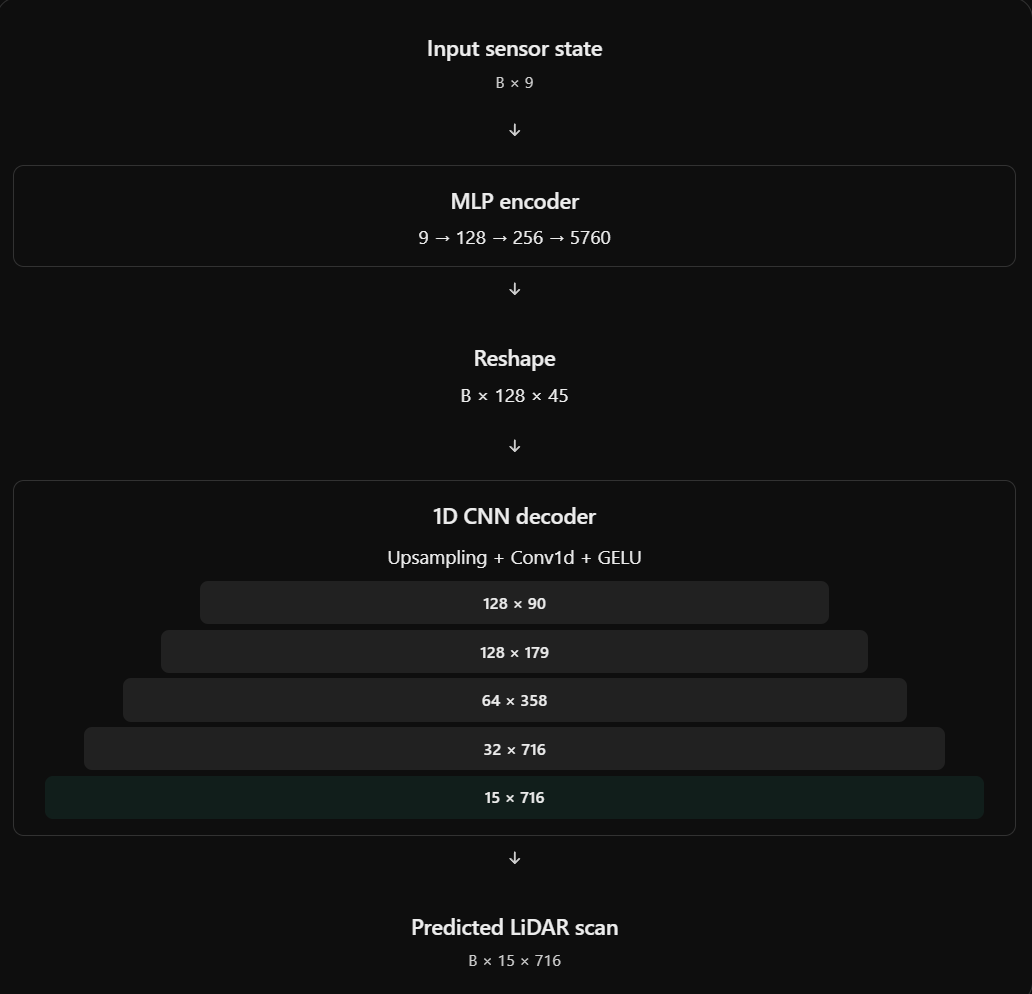

In [20]:
###################################################################
## PRE-PROCESSING FUNCTION
###################################################################
def encode_sensor_state(raw_states):
    
    if raw_states.ndim < 1 or raw_states.shape[-1] != 9:
        raise ValueError(
            "Expected raw sensor states with last dimension 9."
        )

    raw_states = raw_states.float()
    angles = raw_states[..., 6:9]

    angle_features = torch.stack((torch.sin(angles), torch.cos(angles)), dim=-1)
    angle_features = angle_features.flatten(start_dim=-2)

    return torch.cat((raw_states[..., :6], angle_features), dim=-1)

In [21]:
class PoseToRangeCNN(nn.Module):
    """12 encoded state features -> [batch, 15, 716] scan."""
    def __init__(self, model_config):
        super().__init__()
        self.model_config = copy.deepcopy(model_config)
        c = self.model_config
        activation_types = {"gelu": nn.GELU, "relu": nn.ReLU, "silu": nn.SiLU,
                            "identity": nn.Identity, "softplus": nn.Softplus}
        self.latent_channels = c["latent_channels"]
        self.latent_length = c["latent_length"]

        widths = [c["input_features"], *c["encoder_hidden"],
                  self.latent_channels * self.latent_length]
        ############################################################################
        
        encoder = []
        for i, (in_features, out_features) in enumerate(zip(widths[:-1], widths[1:])):
                
                encoder.append(nn.Linear(in_features, out_features))

                if i < len(widths) - 2:
                    encoder.append(activation_types[c["hidden_activation"]]())
                    encoder.append(nn.Dropout(p=0.1))
        self.encoder = nn.Sequential(*encoder)
        
        #############################################################################
        
        decoder = []
        in_channels = self.latent_channels
        last = len(c["decoder_channels"]) - 1
        for i, (out_channels, length, kernel) in enumerate(zip(
            c["decoder_channels"], c["decoder_lengths"], c["kernel_sizes"]
        )):
            decoder.extend([
                nn.Upsample(size=length, mode=c["upsample_mode"],
                            align_corners=c["align_corners"]),
                nn.Conv1d(in_channels, out_channels, kernel_size=kernel,
                          padding=kernel // 2),
            ])
            activation = c["hidden_activation"] if i != last else c["output_activation"]
            decoder.append(activation_types[activation]())
            in_channels = out_channels
        self.decoder = nn.Sequential(*decoder)
        
        ############################################################################

    def forward(self, sensor_state):
        features = self.encoder(sensor_state)
        features = features.reshape(
            sensor_state.shape[0], self.latent_channels, self.latent_length
        )
        return self.decoder(features)


In [22]:
# Verify the complete raw-state -> angle encoding -> scan prediction path.
check_device = torch.device("cuda", CONFIG["runtime"]["gpu_index"])
with torch.inference_mode():
    check_model = PoseToRangeCNN(CONFIG["model"]).to(check_device)
    check_states = torch.zeros(2, 9, device=check_device)
    check_output = check_model(encode_sensor_state(check_states))
    assert check_output.shape == (2, 15, 716)
    print("Verified model output:", tuple(check_output.shape))
del check_model, check_states, check_output


Verified model output: (2, 15, 716)


In [23]:
import csv
import logging
import os
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
from matplotlib.ticker import MaxNLocator


def seed_training(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def write_json(path, value, retries=10, delay=0.05):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    payload = json.dumps(value, indent=2, allow_nan=False)
    for attempt in range(retries):
        try:
            temporary.write_text(payload, encoding="utf-8")
            os.replace(temporary, path)
            break
        except PermissionError:
            if attempt == retries - 1:
                raise
            time.sleep(delay * (attempt + 1))
        finally:
            try:
                temporary.unlink(missing_ok=True)
            except PermissionError:
                pass


def save_checkpoint(path, checkpoint):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    try:
        torch.save(checkpoint, temporary)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def create_training_logger(log_file):
    logger = logging.Logger("pose_to_range", level=logging.INFO)
    logger.propagate = False
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S"
    )
    for handler in (
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(log_file, encoding="utf-8"),
    ):
        handler.setFormatter(formatter)
        logger.addHandler(handler)
    return logger


def log_epoch(logger, *, epoch, epochs, train_mse, val_mse, val_mae,
              learning_rate, elapsed_s, improved, stale_epochs, patience):
    status = "BEST" if improved else f"stale={stale_epochs}/{patience}"
    logger.info(
        "epoch=%03d/%03d | train_mse=%.5f | val_mse=%.5f | "
        "val_rmse=%.4f | val_mae=%.4f | lr=%.2e | %.1fs | %s",
        epoch, epochs, train_mse, val_mse, math.sqrt(val_mse),
        val_mae, learning_rate, elapsed_s, status,
    )


def plot_run_history(run_dir, *, show):
    """Read persisted metrics; works after restarting the notebook kernel."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    history = json.loads((run_dir / "metrics.json").read_text(encoding="utf-8"))
    if not history["epoch"]:
        raise ValueError("This run has no completed epochs to plot.")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    best_index = int(np.argmin(history["val_mse"]))
    best_epoch = history["epoch"][best_index]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for ax, keys, title, ylabel in (
        (axes[0], ("train_mse", "val_mse"), "Training and validation loss", "MSE (m²)"),
        (axes[1], ("train_rmse", "val_rmse"), "Training and validation range error", "RMSE (m)"),
    ):
        for key, label in zip(keys, ("Train")):
            ax.plot(history["epoch"][150:], history[key][150:], label=label[150:])
        ax.axvline(best_epoch, color="gray", linestyle="--",
                   label=f"Best validation: epoch {best_epoch}")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        ax.grid(alpha=0.25)
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    fig.savefig(plots / "loss_curves.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.plot(history["epoch"], history["learning_rate"], label="LR used for epoch")
    ax.set(title="Cosine learning-rate schedule", xlabel="Epoch", ylabel="Learning rate")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    fig.savefig(plots / "learning_rate.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)


def plot_validation_example(model, val_data, run_dir, *, show):
    """Compare a measured scan with the best model's prediction."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    p = config["plots"]
    index = p["scan_index"]
    if index >= len(val_data):
        raise ValueError("plots.scan_index exceeds the validation dataset.")
    state, target = val_data[index]
    device = next(model.parameters()).device
    amp_dtype = torch.bfloat16 if config["runtime"]["amp_dtype"] == "bf16" else torch.float16
    model.eval()
    with torch.inference_mode(), torch.autocast(device.type, dtype=amp_dtype):
        encoded = encode_sensor_state(
            state.unsqueeze(0).to(device, dtype=torch.float32)
        )
        prediction = model(encoded)[0].float().cpu().numpy()
    measured = target.detach().cpu().numpy()
    error = np.abs(prediction - measured)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    for ax, values, title in zip(
        axes, (measured, prediction, error),
        ("Measured range", "Predicted range (best checkpoint)", "Absolute range error"),
    ):
        kwargs = dict(vmin=p["range_min_m"], vmax=p["range_max_m"])
        if ax is axes[2]:
            kwargs = dict(vmin=0, vmax=max(float(error.max()), 1e-9))
        im = ax.imshow(values, aspect="auto", origin="lower",
                       cmap=p["colormap"], **kwargs)
        ax.set(title=title, xlabel="Azimuth bin", ylabel="Elevation bin")
        fig.colorbar(im, ax=ax, label="Meters")
    fig.suptitle(f"Validation sample {index} | MAE = {error.mean():.4f} m")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    fig.savefig(plots / "validation_scan.png", dpi=p["dpi"])
    if show:
        plt.show()
    plt.close(fig)


### 4. Saved output for each run

In [24]:
print("Output root:", OUTPUT_ROOT)
print("Each run gets a new folder containing config.json, source.json, splits.json, training.log,")
print("metrics.csv, metrics.json, summary.json, best.pt, last.pt, and plots/.")


Output root: A:\Projects\ARES\results\output_directoryZ\single_episode
Each run gets a new folder containing config.json, source.json, splits.json, training.log,
metrics.csv, metrics.json, summary.json, best.pt, last.pt, and plots/.


### 5. Load one episode and freeze chronological scan folds

Only the selected episode is loaded. Training uses its earlier scans and validation
uses its later scans. The scan IDs and timestamps stay disjoint; training batches
are shuffled only after the split. No episode count or North/East grouping is needed.
With checksum verification enabled, the matching export audit is located automatically.

In [25]:
import hashlib
from types import SimpleNamespace


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def build_dataset(repo_root, episode_path, train_fraction, val_fraction, *,
                  split_policy, verify_hashes):
    """Load only the selected episode and freeze disjoint chronological scan folds."""
    root = Path(repo_root).expanduser().resolve()
    episode_dir = resolve_episode_directory(root, episode_path)
    manifest_path = episode_dir / "manifest.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(f"Missing raw episode manifest: {manifest_path}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8-sig"))
    episode_id = episode_dir.name
    if str(manifest["runId"]) != episode_id:
        raise ValueError("The raw folder name differs from the manifest episode ID.")
    if split_policy != "chronological":
        raise ValueError("This single-path notebook uses a chronological scan split.")
    if not (math.isfinite(train_fraction) and math.isfinite(val_fraction)
            and train_fraction > 0 and val_fraction > 0
            and math.isclose(train_fraction + val_fraction, 1, rel_tol=0, abs_tol=1e-12)):
        raise ValueError("Positive train/validation fractions must sum to one.")

    # The raw folder supplies identity; the existing Python export supplies aligned scans.
    npz_path = root / "data" / "processed" / "lidar_episode_v1" / episode_id / "episode.npz"
    if not npz_path.is_file():
        raise FileNotFoundError(
            f"No Python export for selected raw episode: {npz_path}. "
            "Export this episode to the existing lidar_episode_v1 format first."
        )
    npz_sha256 = file_sha256(npz_path)
    report_path = None
    expected_count = None
    if verify_hashes:
        matches = []
        for candidate in sorted((root / "data" / "batches").glob("*/python_export_qa.json")):
            report = json.loads(candidate.read_text(encoding="utf-8-sig"))
            entries = [item for item in report.get("files", []) if item["runId"] == episode_id]
            if entries:
                if report.get("allExportChecksPassed") is not True:
                    raise ValueError(f"Selected episode's export audit did not pass: {candidate}")
                matches.extend((candidate, entry) for entry in entries)
        if not matches:
            raise ValueError(
                "No export checksum report found for this episode. Supply its export audit "
                "or explicitly set data.verify_hashes=False for an unaudited export.")
            
        if any(entry["npzSha256"] != npz_sha256 for _, entry in matches):
            raise ValueError("Selected episode's NPZ checksum differs from its export report.")
        
        if len({int(entry["scanCount"]) for _, entry in matches}) != 1:
            raise ValueError("Export reports disagree on this episode's scan count.")
        report_path, entry = matches[0]
        expected_count = int(entry["scanCount"])

    fields = ("time_s", "sample_index", "position_ned_m", "velocity_ned_mps",
              "attitude_ned_rpy_rad", "lidar_ranges_m", "lidar_valid_return_mask",
              "lidar_availability_mask", "lidar_missing_mask", "lidar_enabled")
    
    with np.load(npz_path, allow_pickle=False) as archive:
        required = set(fields) | {"run_id", "schema_version", "metadata_json"}
        if not required.issubset(archive.files):
            raise ValueError(f"Selected NPZ is missing fields: {required - set(archive.files)}")
        if (str(archive["run_id"].item()) != episode_id
                or str(archive["schema_version"].item()) != "ares-python-lidar-episode-v1"):
            raise ValueError("Selected NPZ episode identity or schema is invalid.")
        export_metadata = json.loads(str(archive["metadata_json"].item()))
        if (export_metadata["lidar_grid_size"] != [15, 716]
                or export_metadata["lidar_channel_order"] !=
                "elevation-index-fastest-then-azimuth-index"):
            raise ValueError("Selected episode has incompatible LiDAR beam ordering.")
        episode = {name: archive[name] for name in fields}

    times = np.asarray(episode["time_s"], dtype=np.float64)
    count = len(times)
    if count < 2 or times.shape != (count,) or not np.isfinite(times).all():
        raise ValueError("An episode needs at least two finite timestamps.")
    
    if not np.allclose(np.diff(times), 0.1, rtol=0, atol=1e-6):
        raise ValueError("Expected strictly increasing, aligned 10 Hz scan timestamps.")
    
    if expected_count is not None and count != expected_count:
        raise ValueError("Episode scan count differs from its export report.")
    
    if not np.array_equal(episode["sample_index"], np.arange(1, count + 1)):
        raise ValueError("Episode sample indices must be contiguous and one-based.")
    
    for field in ("position_ned_m", "velocity_ned_mps", "attitude_ned_rpy_rad"):
        if episode[field].shape != (count, 3) or not np.isfinite(episode[field]).all():
            raise ValueError(f"Invalid state array: {field}")
    ranges = episode["lidar_ranges_m"]
    if ranges.shape != (count, 15 * 716) or not np.isfinite(ranges).all():
        raise ValueError("Expected finite full-resolution [T, 10740] ranges.")
    for field in ("lidar_valid_return_mask", "lidar_availability_mask", "lidar_missing_mask"):
        if episode[field].shape != ranges.shape or not np.isin(episode[field], [0, 1]).all():
            raise ValueError(f"Invalid LiDAR mask: {field}")
    if (episode["lidar_enabled"].shape != (count,)
            or not np.equal(episode["lidar_enabled"], True).all()
            or not episode["lidar_availability_mask"].all()
            or episode["lidar_missing_mask"].any()):
        raise ValueError("Selected episode must contain measured, healthy LiDAR.")
    maximum = float(manifest["static"]["maximum_sensor_range_m"])
    valid = episode["lidar_valid_return_mask"].astype(bool)
    if (not math.isclose(maximum, 7.0) or not ((ranges >= 0) & (ranges <= maximum)).all()
            or not (ranges[valid] > 0).all() or not (ranges[~valid] == maximum).all()):
        raise ValueError("Invalid recorded range or no-return encoding.")

    states = np.column_stack((
        episode["position_ned_m"], episode["velocity_ned_mps"],
        episode["attitude_ned_rpy_rad"],
    )).astype(np.float32, copy=False)
    scans = ranges.reshape(count, 716, 15).transpose(0, 2, 1).astype(np.float32, copy=False)
    boundary = int(math.floor(count * train_fraction))
    if boundary < 1 or boundary >= count:
        raise ValueError("The chosen fractions leave an empty train or validation fold.")
    
    split_ranges = {"train": [0, boundary], "validation": [boundary, count]}
    splits = {
        name: [f"{episode_id}:{index + 1}" for index in range(start, stop)]
        for name, (start, stop) in split_ranges.items()
    }
    
    source_metadata = {
        "episode_id": episode_id, "episode_path": str(episode_dir),
        "npz_path": str(npz_path), "npz_sha256": npz_sha256,
        "manifest_sha256": file_sha256(manifest_path),
        "checksum_verified": verify_hashes,
        "checksum_report": str(report_path) if report_path is not None else None,
        "split_policy": split_policy, "total_scans": count,
        "split_ranges_zero_based_end_exclusive": split_ranges,
        "validation_scope": "later scans of the same path; not unseen-path evaluation",
    }
    return SimpleNamespace(
        episode_id=episode_id, states=states, scans=scans, times=times,
        splits=splits, split_ranges=split_ranges, source_metadata=source_metadata,
        diagnostics={name: {
            "scan_count": stop - start,
            "first_time_s": float(times[start]), "last_time_s": float(times[stop - 1]),
        } for name, (start, stop) in split_ranges.items()},
    )


In [26]:
validate_config(CONFIG)
d = CONFIG["data"]
corpus = build_dataset(
    REPO_ROOT, episode_path=d["episode_path"],
    train_fraction=d["train_fraction"], val_fraction=d["val_fraction"],
    split_policy=d["split_policy"], verify_hashes=d["verify_hashes"],
)
print("Episode:", corpus.episode_id)
for name, ids in corpus.splits.items():
    info = corpus.diagnostics[name]
    print(f"{name}: {len(ids)} scans; {info['first_time_s']:.1f}s to {info['last_time_s']:.1f}s")
assert set(corpus.splits["train"]).isdisjoint(corpus.splits["validation"])


Episode: f9ab72ef-e1d7-4479-8faa-03bb5b36776c
train: 241 scans; 0.0s to 24.0s
validation: 61 scans; 24.1s to 30.1s


### 6. Training function: the same mini-batches and cosine decay

The GPU training loop, scheduler, checkpoints, telemetry and plots follow the baseline.
Provenance checks now verify disjoint scan IDs within the one selected episode.
The run also saves source.json with the episode path, hashes and time split.

In [27]:
def train_cnn_mlp_baseline(model, train_data, val_data, *, config, split_ids, source_metadata):
    """Train one configured run; return best model, history, and its output folder."""
    config = copy.deepcopy(config)
    validate_config(config)
    t, r, s = (config[key] for key in ("training", "runtime", "scheduler"))
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable.")
    if r["gpu_index"] >= torch.cuda.device_count():
        raise ValueError("Configured GPU index is unavailable.")
    torch.cuda.set_device(r["gpu_index"])
    if r["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
        raise ValueError("Configured BF16 is unsupported; explicitly choose fp16.")
    if model.model_config != config["model"]:
        raise ValueError("Model architecture differs from the run configuration.")

    for name, dataset in (("train", train_data), ("validation", val_data)):
        if not len(dataset):
            raise ValueError(f"{name} dataset is empty.")
        state, scan = dataset[0]
        if state.shape != (9,) or scan.shape != (15, 716):
            raise ValueError(f"{name}: expected raw state [9], scan [15, 716].")
        if state.device.type != "cpu" or scan.device.type != "cpu":
            raise ValueError("Keep dataset tensors on the CPU for batched transfers.")
    if config["plots"]["scan_index"] >= len(val_data):
        raise ValueError("plots.scan_index exceeds the validation dataset.")
    if set(split_ids) != {"train", "validation"}:
        raise ValueError("Provide chronological train/validation scan IDs.")
    selected_id = resolve_episode_directory(
        config["paths"]["repo_root"], config["data"]["episode_path"]
    ).name
    count = len(train_data) + len(val_data)
    boundary = int(math.floor(count * config["data"]["train_fraction"]))
    expected_ranges = {"train": [0, boundary], "validation": [boundary, count]}
    expected_ids = {
        name: [f"{selected_id}:{i + 1}" for i in range(start, stop)]
        for name, (start, stop) in expected_ranges.items()
    }
    if split_ids != expected_ids:
        raise ValueError("Scan IDs must cover exactly the selected episode in chronological folds.")
    if (len(train_data) != boundary or source_metadata["episode_id"] != selected_id
            or source_metadata["total_scans"] != count
            or source_metadata["split_policy"] != "chronological"
            or source_metadata["split_ranges_zero_based_end_exclusive"] != expected_ranges):
        raise ValueError("Source provenance and dataset scan counts differ from the selected episode.")

    seed_training(config["run"]["seed"])
    device = torch.device("cuda", r["gpu_index"])
    model = model.to(device, dtype=torch.float32)
    torch.set_float32_matmul_precision(r["matmul_precision"])
    torch.backends.cudnn.benchmark = r["cudnn_benchmark"]
    
    amp_dtype = torch.bfloat16 if r["amp_dtype"] == "bf16" else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
    generator = torch.Generator().manual_seed(config["run"]["seed"])
    loader_options = dict(
        batch_size=t["batch_size"], pin_memory=r["pin_memory"],
        num_workers=r["num_workers"], persistent_workers=r["persistent_workers"],
        drop_last=False)
    train_loader = DataLoader(train_data, shuffle=True, generator=generator, **loader_options)
    val_loader = DataLoader(val_data, shuffle=False, **loader_options)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=t["learning_rate"], weight_decay=t["weight_decay"],
        betas=tuple(t["betas"]), eps=t["eps"], fused=r["fused_adamw"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=s["t_max_epochs"], eta_min=s["min_lr"]
    )

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    run_dir = Path(config["paths"]["output_root"]).expanduser().resolve() / (
        f'{config["run"]["name"]}_{stamp}_{datetime.now().strftime("%Y%m%d_%H%M%S")}'
    )
    run_dir.mkdir(parents=True, exist_ok=False)
    logger = create_training_logger(run_dir / "training.log")
    keys = ("epoch", "train_mse", "val_mse", "train_rmse", "val_rmse",
            "val_mae", "learning_rate", "next_learning_rate", "elapsed_s",
            "gpu_peak_allocated_mib", "stale_epochs", "improved")
    history = {key: [] for key in keys}
    best_val, best_epoch, stale_epochs = float("inf"), None, 0
    status = "running"
    metadata = {
        "run_dir": str(run_dir), "status": status,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "torch_version": str(torch.__version__),
        "gpu": torch.cuda.get_device_name(device),
        "train_scans": len(train_data), "validation_scans": len(val_data),
        "raw_state_order": ["north", "east", "down", "vn", "ve", "vd",
                            "roll_rad", "pitch_rad", "yaw_rad"],
        "angle_encoding": "sin_roll, cos_roll, sin_pitch, cos_pitch, sin_yaw, cos_yaw",
        "scan_layout": "[elevation=15, azimuth=716]; measured no-return beams remain 7m",
    }

    metadata.update(source_metadata)

    try:
        write_json(run_dir / "source.json", source_metadata)
        write_json(run_dir / "config.json", config)
        write_json(run_dir / "splits.json", split_ids)
        write_json(run_dir / "summary.json", metadata)
        write_json(run_dir / "metrics.json", history)
        logger.info("Run output: %s", run_dir)
        with (run_dir / "metrics.csv").open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=keys)
            writer.writeheader()
            stream.flush()

            for epoch in range(1, t["epochs"] + 1):
                epoch_start = perf_counter()
                torch.cuda.reset_peak_memory_stats(device)
                lr_used = optimizer.param_groups[0]["lr"]
                model.train()
                train_error = torch.zeros((), device=device)
                train_elements = 0
                for states, scans in train_loader:
                    states = encode_sensor_state(
                        states.to(device, dtype=torch.float32, non_blocking=True)
                    )
                    scans = scans.to(device, dtype=torch.float32, non_blocking=True)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.autocast("cuda", dtype=amp_dtype):
                        predictions = model(states)
                        if predictions.shape != scans.shape:
                            raise ValueError("Prediction and target shapes differ.")
                        loss = F.mse_loss(predictions, scans)
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                    train_error += loss.detach() * scans.numel()
                    train_elements += scans.numel()

                model.eval()
                val_error = torch.zeros((), device=device)
                val_absolute = torch.zeros((), device=device)
                val_elements = 0
                with torch.inference_mode():
                    for states, scans in val_loader:
                        states = encode_sensor_state(
                            states.to(device, dtype=torch.float32, non_blocking=True)
                        )
                        scans = scans.to(device, dtype=torch.float32, non_blocking=True)
                        with torch.autocast("cuda", dtype=amp_dtype):
                            predictions = model(states)
                            if predictions.shape != scans.shape:
                                raise ValueError("Prediction and target shapes differ.")
                            loss = F.mse_loss(predictions, scans)
                        val_error += loss * scans.numel()
                        val_absolute += (predictions.float() - scans).abs().sum()
                        val_elements += scans.numel()

                train_mse = (train_error / train_elements).item()
                val_mse = (val_error / val_elements).item()
                val_mae = (val_absolute / val_elements).item()
                if not all(math.isfinite(value) and value >= 0
                           for value in (train_mse, val_mse, val_mae)):
                    raise FloatingPointError("Non-finite loss; check inputs and learning rate.")
                improved = val_mse < best_val
                if improved:
                    best_val, best_epoch, stale_epochs = val_mse, epoch, 0
                else:
                    stale_epochs += 1

                # One scheduler step AFTER optimizer updates, once per epoch.
                scheduler.step()
                row = dict(
                    epoch=epoch, train_mse=train_mse, val_mse=val_mse,
                    train_rmse=math.sqrt(train_mse), val_rmse=math.sqrt(val_mse),
                    val_mae=val_mae, learning_rate=lr_used,
                    next_learning_rate=optimizer.param_groups[0]["lr"],
                    elapsed_s=perf_counter() - epoch_start,
                    gpu_peak_allocated_mib=torch.cuda.max_memory_allocated(device) / 2**20,
                    stale_epochs=stale_epochs, improved=improved,
                )
                for key in keys:
                    history[key].append(row[key])
                writer.writerow(row)
                stream.flush()
                write_json(run_dir / "metrics.json", history)

                checkpoint = {
                    "epoch": epoch, "best_epoch": best_epoch,
                    "best_val_mse": best_val, "stale_epochs": stale_epochs,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "torch_rng_state": torch.get_rng_state(),
                    "cuda_rng_states": torch.cuda.get_rng_state_all(),
                    "loader_rng_state": generator.get_state(),
                    "config": config, "history": history,
                    "source_metadata": source_metadata, "split_ids": split_ids,
                }
                save_checkpoint(run_dir / "last.pt", checkpoint)
                if improved:
                    save_checkpoint(run_dir / "best.pt", checkpoint)
                interval = t["save_every_n_epochs"]
                if interval and epoch % interval == 0:
                    save_checkpoint(run_dir / f"epoch_{epoch:04d}.pt", checkpoint)
                log_epoch(
                    logger, epoch=epoch, epochs=t["epochs"],
                    train_mse=train_mse, val_mse=val_mse, val_mae=val_mae,
                    learning_rate=lr_used, elapsed_s=row["elapsed_s"],
                    improved=improved, stale_epochs=stale_epochs, patience=t["patience"],
                )
                # if stale_epochs >= t["patience"]:
                #     status = "early_stopped"
                #     logger.info("Early stopping; best validation epoch=%d.", best_epoch)
                #     break
            else:
                status = "completed"

        checkpoint = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        plot_run_history(run_dir, show=False)
        plot_validation_example(model, val_data, run_dir, show=False)
        metadata.update(
            status=status, completed_epochs=len(history["epoch"]),
            best_epoch=best_epoch, best_val_mse=best_val, best_val_rmse=math.sqrt(best_val),
            last_learning_rate=history["learning_rate"][-1],
            next_learning_rate=history["next_learning_rate"][-1],
        )
        write_json(run_dir / "summary.json", metadata)
        logger.info("Saved checkpoints, metrics and plots: %s", run_dir)
        return model, history, run_dir

    except BaseException as exc:
        logger.exception("Run failed or was interrupted; completed epoch files are retained.")
        metadata.update(
            status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            error_type=type(exc).__name__, error=str(exc),
            completed_epochs=len(history["epoch"]),
            best_epoch=best_epoch,
            best_val_mse=best_val if math.isfinite(best_val) else None,
        )
        write_json(run_dir / "summary.json", metadata)
        if history["epoch"]:
            try:
                plot_run_history(run_dir, show=False)
            except Exception:
                logger.exception("Could not save partial loss plots.")
        raise
    finally:
        for handler in list(logger.handlers):
            handler.close()
            logger.removeHandler(handler)


### 7. Build train and validation tensors from the selected episode

In [28]:
def build_train_val_tensors(corpus):
    """Convert the selected episode's fixed chronological folds to CPU tensors."""
    def load_split(name):
        start, stop = corpus.split_ranges[name]
        states = torch.from_numpy(np.ascontiguousarray(corpus.states[start:stop]))
        scans = torch.from_numpy(np.ascontiguousarray(corpus.scans[start:stop]))
        return states, scans
    train_states, train_scans = load_split("train")
    val_states, val_scans = load_split("validation")
    return train_states, train_scans, val_states, val_scans


### 8. Train and save a new single-episode run

The configured seed is applied before model creation. Output folders are unique,
and source.json records the selected episode and exact chronological scan ranges.

In [29]:
train_states, train_scans, val_states, val_scans = build_train_val_tensors(corpus)
train_dataset = TensorDataset(train_states, train_scans)
val_dataset = TensorDataset(val_states, val_scans)
print("Train:", train_states.shape, train_scans.shape)
print("Validation:", val_states.shape, val_scans.shape)


Train: torch.Size([241, 9]) torch.Size([241, 15, 716])
Validation: torch.Size([61, 9]) torch.Size([61, 15, 716])


In [30]:
# Revalidate before execution; each run saves the selected episode's provenance.
validate_config(CONFIG)
seed_training(CONFIG["run"]["seed"])
model, history, run_dir = train_cnn_mlp_baseline(
    PoseToRangeCNN(CONFIG["model"]),
    train_dataset, val_dataset,
    config=CONFIG, split_ids=corpus.splits,
    source_metadata=corpus.source_metadata,
)
print("Run saved to:", run_dir)


20:12:15 | INFO | Run output: A:\Projects\ARES\results\output_directoryZ\single_episode\CNN_MLP_BASELINE_SINGLE_EPISODE_20261113T041215_258339Z_20261112_201215
20:12:16 | INFO | epoch=001/2000 | train_mse=34.95529 | val_mse=29.60865 | val_rmse=5.4414 | val_mae=3.8265 | lr=1.00e-03 | 0.1s | BEST
20:12:17 | INFO | epoch=002/2000 | train_mse=18.44174 | val_mse=15.59070 | val_rmse=3.9485 | val_mae=3.2055 | lr=1.00e-03 | 0.1s | BEST
20:12:18 | INFO | epoch=003/2000 | train_mse=10.42444 | val_mse=8.62181 | val_rmse=2.9363 | val_mae=2.4476 | lr=1.00e-03 | 0.1s | BEST
20:12:19 | INFO | epoch=004/2000 | train_mse=5.60902 | val_mse=4.10502 | val_rmse=2.0261 | val_mae=1.6337 | lr=1.00e-03 | 0.1s | BEST
20:12:20 | INFO | epoch=005/2000 | train_mse=2.67253 | val_mse=3.86082 | val_rmse=1.9649 | val_mae=1.7061 | lr=1.00e-03 | 0.1s | BEST
20:12:21 | INFO | epoch=006/2000 | train_mse=1.56634 | val_mse=0.79436 | val_rmse=0.8913 | val_mae=0.7063 | lr=1.00e-03 | 0.1s | BEST
20:12:22 | INFO | epoch=007/200

KeyboardInterrupt: 

### 9. Visualize saved results

The loss and learning-rate plots read this run's saved metrics. The scan comparison
uses the returned best-validation model. All three figures are also saved in plots/.

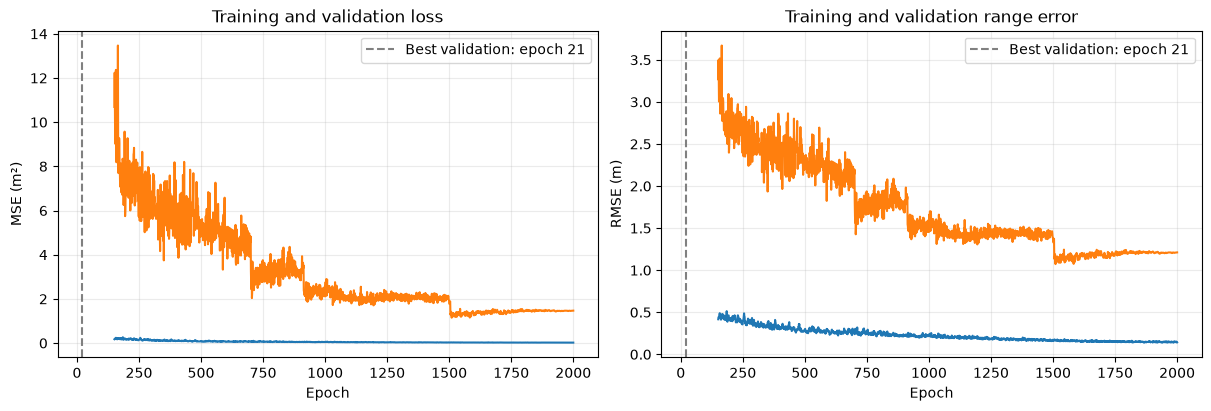

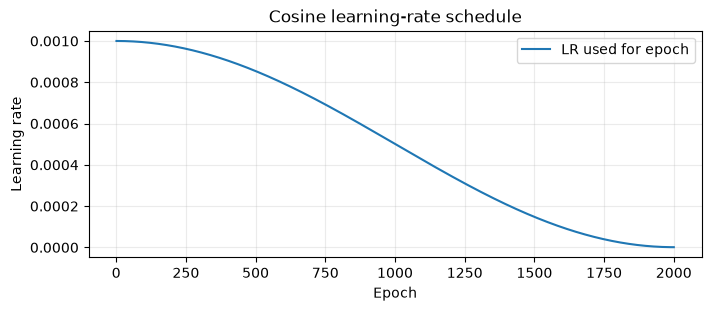

In [ ]:
plot_run_history(run_dir, show=True)


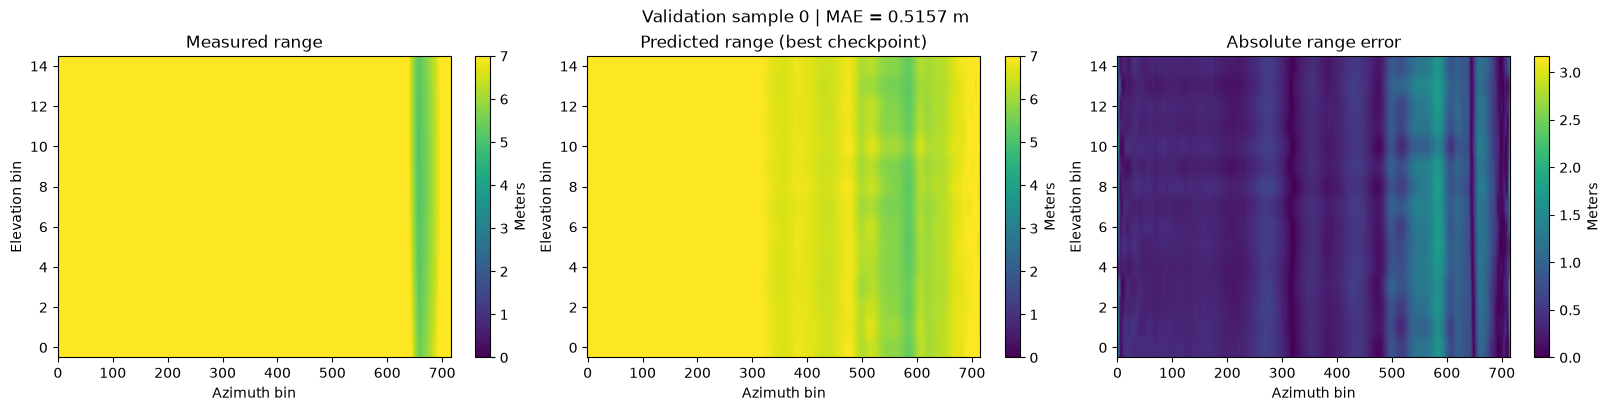

In [ ]:
plot_validation_example(model, val_dataset, run_dir, show=True)
